In [1]:
import platform, random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("Semilla:", SEED)

Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
Semilla: 42


In [2]:
# Para leer un archivo de Excel (.xlsx o .xls)
# Nota: Puede que necesites instalar openpyxl ejecutando: !pip install openpyxl
df = pd.read_excel("/content/ENB2012_data.xlsx")
df_raw = df.copy()
df

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28
...,...,...,...,...,...,...,...,...,...,...
763,0.64,784.0,343.0,220.50,3.5,5,0.4,5,17.88,21.40
764,0.62,808.5,367.5,220.50,3.5,2,0.4,5,16.54,16.88
765,0.62,808.5,367.5,220.50,3.5,3,0.4,5,16.44,17.11
766,0.62,808.5,367.5,220.50,3.5,4,0.4,5,16.48,16.61


In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

In [4]:
print("TAMAÑO")
print(df.shape)

TAMAÑO
(768, 10)


In [5]:
print("SABER LAS COLUMNAS")
print(df.columns)

SABER LAS COLUMNAS
Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')


In [6]:
calidad = {
    "filas_iniciales": df_raw.shape[0],
    "columnas_iniciales": df_raw.shape[1],
    "nulos_iniciales": int(df_raw.isnull().sum().sum()),
    "duplicados_iniciales": int(df_raw.duplicated().sum()),
}
print(calidad)

{'filas_iniciales': 768, 'columnas_iniciales': 10, 'nulos_iniciales': 0, 'duplicados_iniciales': 0}


In [7]:
print("ELIMINAR DUPLICADOS")
n_antes = len(df)
df = df.drop_duplicates()
calidad["duplicados_eliminados"] = n_antes - len(df)
print(df.shape)

ELIMINAR DUPLICADOS
(768, 10)


In [8]:
print("DATOS NULOS")
print(df.isnull().sum().reset_index())

DATOS NULOS
  index  0
0    X1  0
1    X2  0
2    X3  0
3    X4  0
4    X5  0
5    X6  0
6    X7  0
7    X8  0
8    Y1  0
9    Y2  0


In [9]:
print("ELIMINAR NULOS")
n_antes = len(df)
df = df.dropna()
calidad["filas_con_nulos_eliminadas"] = n_antes - len(df)
df = df.reset_index(drop=True)
print(df.shape)

ELIMINAR NULOS
(768, 10)


In [10]:
print("TRATAMIENTO DE OUTLIERS (VALORES ATÍPICOS)")

# Solo variables continuas (X6 y X8 son categóricas y se validan aparte)
columnas_numericas = ["X1", "X2", "X3", "X4", "X5", "X7", "Y1", "Y2"]

filas = []
for col in columnas_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    n_out = int(((df[col] < limite_inferior) | (df[col] > limite_superior)).sum())
    filas.append({"variable": col, "Q1": Q1, "Q3": Q3,
                  "lim_inf": limite_inferior, "lim_sup": limite_superior,
                  "n_outliers": n_out,
                  "pct_outliers": round(100 * n_out / len(df), 2)})

tabla_outliers = pd.DataFrame(filas).round(3)
calidad["outliers_detectados"] = int(tabla_outliers["n_outliers"].sum())
calidad["outliers_corregidos"] = 0
display(tabla_outliers)

TRATAMIENTO DE OUTLIERS (VALORES ATÍPICOS)


,variable,Q1,Q3,lim_inf,lim_sup,n_outliers,pct_outliers
0,X1,0.682,0.830,0.461,1.051,0,0.0
1,X2,606.375,741.125,404.250,943.250,0,0.0
2,X3,294.000,343.000,220.500,416.500,0,0.0
3,X4,140.875,220.500,21.438,339.938,0,0.0
4,X5,3.500,7.000,-1.750,12.250,0,0.0
5,X7,0.100,0.400,-0.350,0.850,0,0.0
6,Y1,12.992,31.668,-15.020,59.680,0,0.0
7,Y2,15.620,33.132,-10.649,59.401,0,0.0


In [11]:
print("ESTANDARIZACIÓN DE FORMATOS Y TIPOS DE DATOS")

# 1. Estandarizar nombres de columnas (renombrar a nombres descriptivos y consistentes)
nombres_columnas = {
    'X1': 'compactacion_relativa',
    'X2': 'area_superficie',
    'X3': 'area_pared',
    'X4': 'area_techo',
    'X5': 'altura_total',
    'X6': 'orientacion',
    'X7': 'area_acristalamiento',
    'X8': 'distribucion_acristalamiento',
    'Y1': 'carga_calefaccion',
    'Y2': 'carga_refrigeracion'
}
df = df.rename(columns=nombres_columnas)

# 2. Verificar y estandarizar tipos de datos (por ejemplo, asegurar que ciertas columnas sean float o int)
df['orientacion'] = df['orientacion'].astype(int)
df['distribucion_acristalamiento'] = df['distribucion_acristalamiento'].astype(int)

# Mostramos los nuevos tipos de datos y las primeras filas
print("\nTipos de datos actualizados:")
print(df.dtypes)
print("\nPrimeras filas del DataFrame estandarizado:")
df.head()

ESTANDARIZACIÓN DE FORMATOS Y TIPOS DE DATOS

Tipos de datos actualizados:
compactacion_relativa           float64
area_superficie                 float64
area_pared                      float64
area_techo                      float64
altura_total                    float64
orientacion                       int64
area_acristalamiento            float64
distribucion_acristalamiento      int64
carga_calefaccion               float64
carga_refrigeracion             float64
dtype: object

Primeras filas del DataFrame estandarizado:


,compactacion_relativa,area_superficie,area_pared,area_techo,altura_total,orientacion,area_acristalamiento,distribucion_acristalamiento,carga_calefaccion,carga_refrigeracion
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [12]:
valores_validos = {
    "orientacion": {2, 3, 4, 5},
    "distribucion_acristalamiento": {0, 1, 2, 3, 4, 5},
    "area_acristalamiento": {0.0, 0.1, 0.25, 0.4},
}
calidad["valores_invalidos"] = {}
for col, validos in valores_validos.items():
    n_inv = int((~df[col].isin(validos)).sum())
    calidad["valores_invalidos"][col] = n_inv
    print(f"{col}: {n_inv} valores fuera de {sorted(validos)}")

# Si no hay vidriería, la distribución debe ser 0 (y viceversa)
incons = int(((df["area_acristalamiento"] == 0) != (df["distribucion_acristalamiento"] == 0)).sum())
calidad["inconsistencias_acristalamiento"] = incons
print("Inconsistencias acristalamiento vs distribución:", incons)

orientacion: 0 valores fuera de [2, 3, 4, 5]
distribucion_acristalamiento: 0 valores fuera de [0, 1, 2, 3, 4, 5]
area_acristalamiento: 0 valores fuera de [0.0, 0.1, 0.25, 0.4]
Inconsistencias acristalamiento vs distribución: 0


In [13]:
from google.colab import files

# 1. Guardar el archivo limpio en el almacenamiento temporal de Colab
df.to_csv("enb2012_limpio.csv", index=False)

# 2. Verificación: leer de nuevo el archivo guardado
df_verificacion = pd.read_csv("enb2012_limpio.csv")
print("Filas y columnas guardadas:", df_verificacion.shape)
print("Coincide con df:", df_verificacion.shape == df.shape)

# 3. Descargar el archivo directamente a tu computador
files.download("enb2012_limpio.csv")

Filas y columnas guardadas: (768, 10)
Coincide con df: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# 1. Crear las variables que hacen falta en el DataFrame
df["carga_total"] = df["carga_calefaccion"] + df["carga_refrigeracion"]
df["razon_calef_refri"] = df["carga_calefaccion"] / df["carga_refrigeracion"]

# 2. Definir las columnas numéricas para el análisis
columnas_numericas = ["compactacion_relativa", "area_superficie", "area_pared", "area_techo",
                      "altura_total", "area_acristalamiento", "carga_calefaccion",
                      "carga_refrigeracion", "carga_total", "razon_calef_refri"]

# 3. Generar la tabla de resumen descriptivo
resumen = df[columnas_numericas].describe().T
resumen["asimetria"] = df[columnas_numericas].skew()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
compactacion_relativa,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98,0.50
area_superficie,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50,-0.13
area_pared,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50,0.53
area_techo,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50,-0.16
altura_total,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00,0.00
area_acristalamiento,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40,-0.06
carga_calefaccion,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10,0.36
carga_refrigeracion,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03,0.40
carga_total,768.0,46.89,19.48,16.95,28.75,40.97,64.34,89.95,0.35
razon_calef_refri,768.0,0.88,0.10,0.54,0.82,0.87,0.97,1.12,-0.33


In [15]:
# 1. Crear la columna 'nivel_eficiencia' basada en rangos de 'carga_total'
# Esto divide el consumo de los edificios en 3 categorías de eficiencia
import pandas as pd

df['nivel_eficiencia'] = pd.qcut(df['carga_total'], q=3, labels=['Alta', 'Media', 'Baja'])

# 2. Ejecutar el conteo de frecuencias de cada categoría
for col in ["orientacion", "distribucion_acristalamiento", "area_acristalamiento",
            "altura_total", "nivel_eficiencia"]:
    print(f"--- Variable: {col} ---")
    print(df[col].value_counts().sort_index())
    print()

--- Variable: orientacion ---
orientacion
2    192
3    192
4    192
5    192
Name: count, dtype: int64

--- Variable: distribucion_acristalamiento ---
distribucion_acristalamiento
0     48
1    144
2    144
3    144
4    144
5    144
Name: count, dtype: int64

--- Variable: area_acristalamiento ---
area_acristalamiento
0.00     48
0.10    240
0.25    240
0.40    240
Name: count, dtype: int64

--- Variable: altura_total ---
altura_total
3.5    384
7.0    384
Name: count, dtype: int64

--- Variable: nivel_eficiencia ---
nivel_eficiencia
Alta     256
Media    256
Baja     256
Name: count, dtype: int64



In [16]:
columnas_numericas = ["compactacion_relativa", "area_superficie", "area_pared", "area_techo",
                      "altura_total", "area_acristalamiento", "carga_calefaccion",
                      "carga_refrigeracion", "carga_total", "razon_calef_refri"]

resumen = df[columnas_numericas].describe().T
resumen["asimetria"] = df[columnas_numericas].skew()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
compactacion_relativa,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98,0.50
area_superficie,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50,-0.13
area_pared,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50,0.53
area_techo,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50,-0.16
altura_total,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00,0.00
area_acristalamiento,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40,-0.06
carga_calefaccion,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10,0.36
carga_refrigeracion,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03,0.40
carga_total,768.0,46.89,19.48,16.95,28.75,40.97,64.34,89.95,0.35
razon_calef_refri,768.0,0.88,0.10,0.54,0.82,0.87,0.97,1.12,-0.33


In [17]:
for col in ["orientacion", "distribucion_acristalamiento", "area_acristalamiento",
            "altura_total", "nivel_eficiencia"]:
    print(col)
    print(df[col].value_counts().sort_index())
    print()

orientacion
orientacion
2    192
3    192
4    192
5    192
Name: count, dtype: int64

distribucion_acristalamiento
distribucion_acristalamiento
0     48
1    144
2    144
3    144
4    144
5    144
Name: count, dtype: int64

area_acristalamiento
area_acristalamiento
0.00     48
0.10    240
0.25    240
0.40    240
Name: count, dtype: int64

altura_total
altura_total
3.5    384
7.0    384
Name: count, dtype: int64

nivel_eficiencia
nivel_eficiencia
Alta     256
Media    256
Baja     256
Name: count, dtype: int64



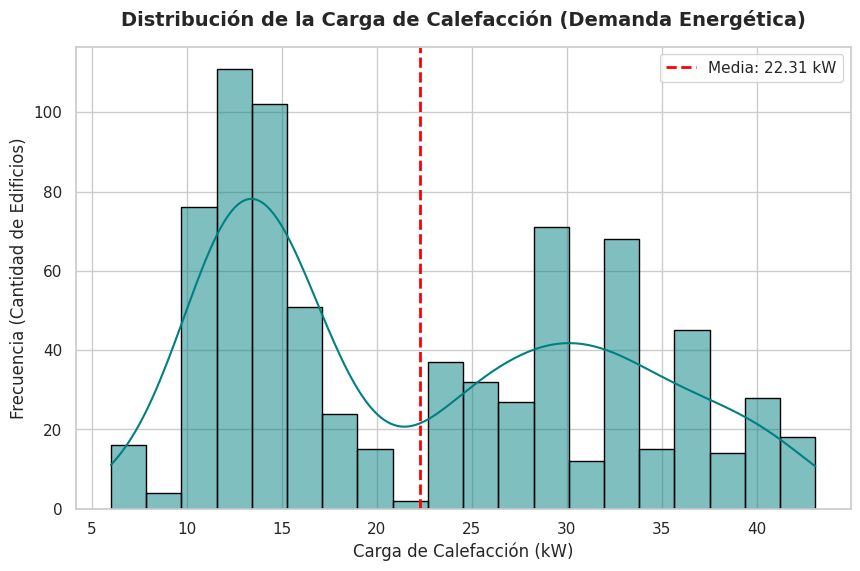

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño y estilo de la gráfica
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Crear el histograma con curva de densidad (KDE)
sns.histplot(data=df, x="carga_calefaccion", kde=True, bins=20, color="teal", edgecolor="black")

# Añadir una línea vertical para indicar la media
media_calefaccion = df["carga_calefaccion"].mean()
plt.axvline(media_calefaccion, color="red", linestyle="--", linewidth=2, label=f"Media: {media_calefaccion:.2f} kW")

# Personalizar títulos y etiquetas
plt.title("Distribución de la Carga de Calefacción (Demanda Energética)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Carga de Calefacción (kW)", fontsize=12)
plt.ylabel("Frecuencia (Cantidad de Edificios)", fontsize=12)
plt.legend(fontsize=11)

# Mostrar el gráfico
plt.show()

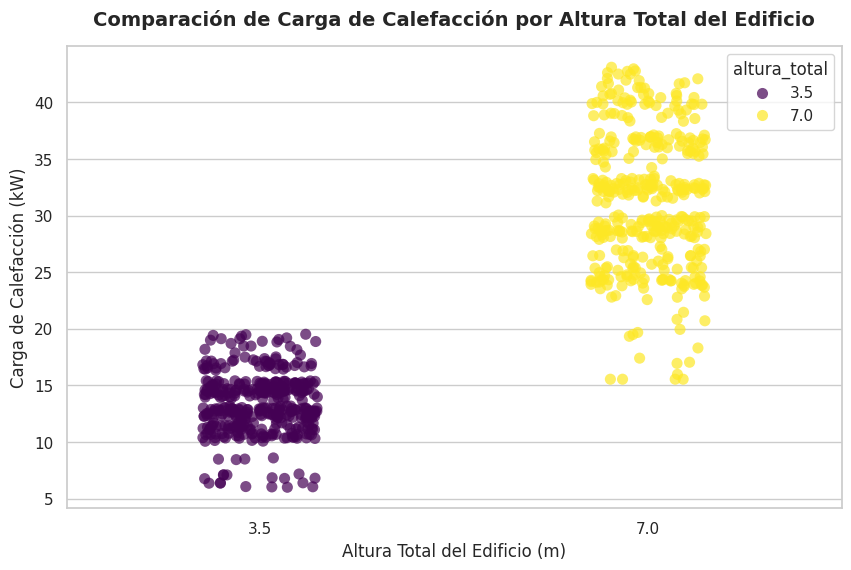

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño y estilo de la gráfica
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Crear el gráfico de dispersión añadiendo un pequeño temblor (jitter)
# en el eje X porque 'altura_total' toma valores muy específicos (3.5 y 7.0)
sns.stripplot(data=df, x="altura_total", y="carga_calefaccion",
              size=8, palette="viridis", hue="altura_total", alpha=0.7, jitter=0.15)

# Personalizar títulos y etiquetas
plt.title("Comparación de Carga de Calefacción por Altura Total del Edificio", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Altura Total del Edificio (m)", fontsize=12)
plt.ylabel("Carga de Calefacción (kW)", fontsize=12)

# Mostrar el gráfico
plt.show()

/tmp/ipykernel_565/795519237.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="area_acristalamiento", y="carga_calefaccion", ax=axes[0], palette="Blues")
/tmp/ipykernel_565/795519237.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="area_acristalamiento", y="carga_refrigeracion", ax=axes[1], palette="Oranges")


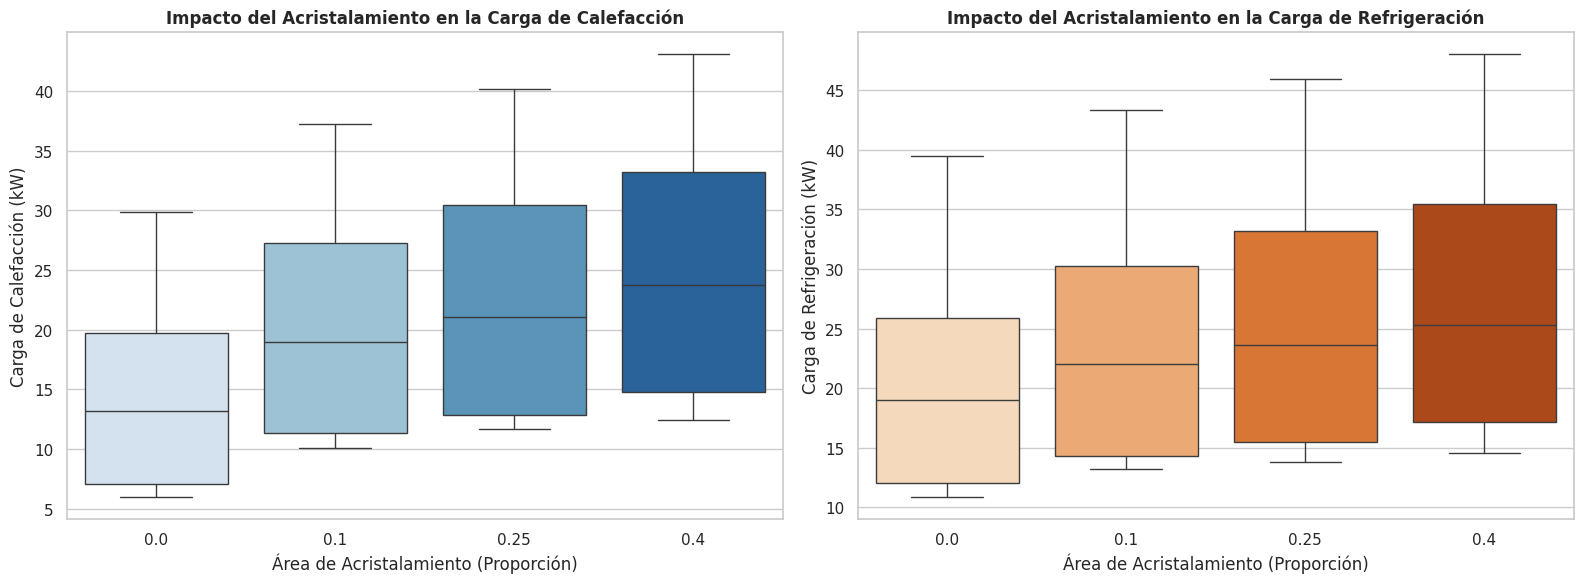

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Impacto del acristalamiento en Calefacción
sns.boxplot(data=df, x="area_acristalamiento", y="carga_calefaccion", ax=axes[0], palette="Blues")
axes[0].set_title("Impacto del Acristalamiento en la Carga de Calefacción", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Área de Acristalamiento (Proporción)")
axes[0].set_ylabel("Carga de Calefacción (kW)")

# Gráfico 2: Impacto del acristalamiento en Refrigeración
sns.boxplot(data=df, x="area_acristalamiento", y="carga_refrigeracion", ax=axes[1], palette="Oranges")
axes[1].set_title("Impacto del Acristalamiento en la Carga de Refrigeración", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Área de Acristalamiento (Proporción)")
axes[1].set_ylabel("Carga de Refrigeración (kW)")

plt.tight_layout()
plt.show()

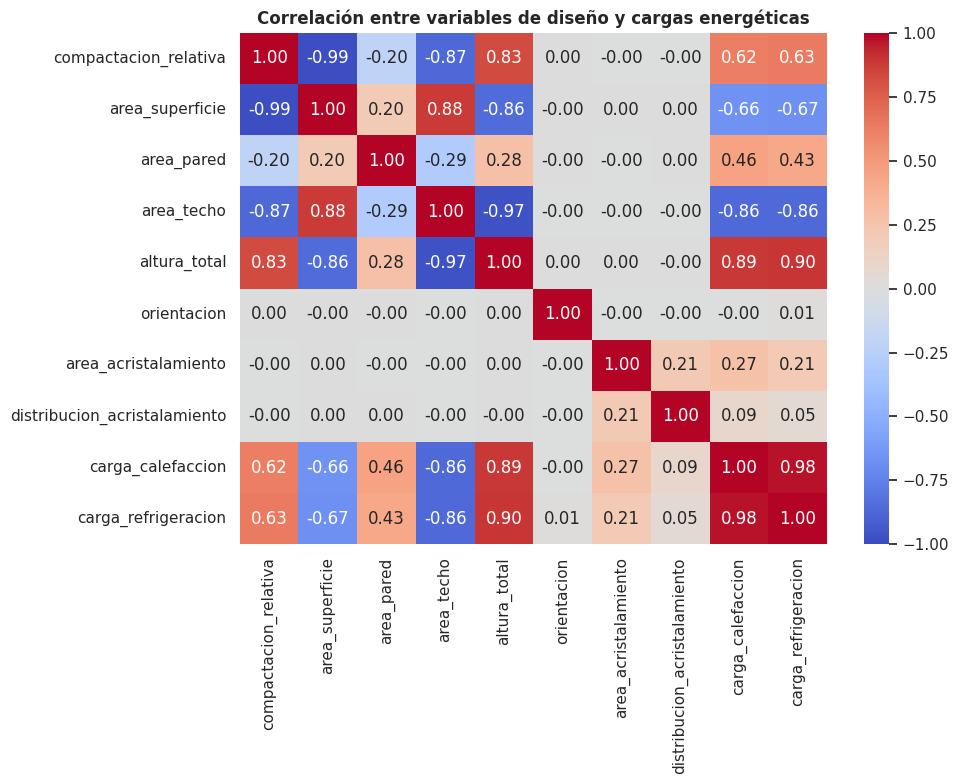

In [21]:
columnas_corr = ["compactacion_relativa", "area_superficie", "area_pared", "area_techo", "altura_total",
                 "orientacion", "area_acristalamiento", "distribucion_acristalamiento",
                 "carga_calefaccion", "carga_refrigeracion"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[columnas_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables de diseño y cargas energéticas", fontweight="bold")
plt.tight_layout()
plt.show()

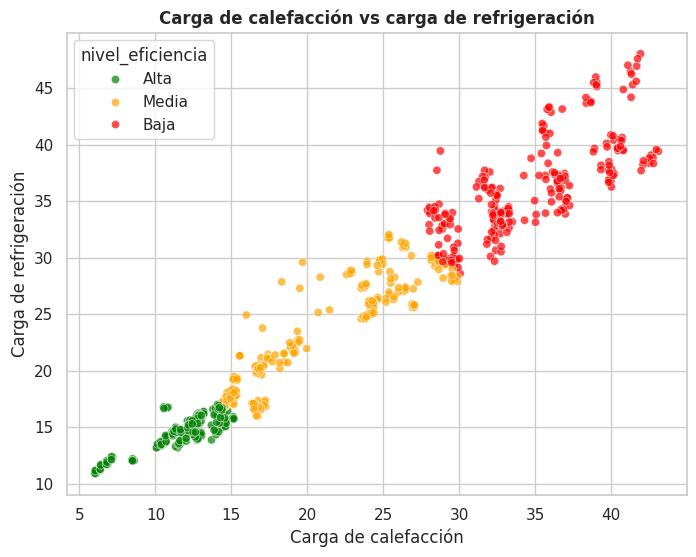

In [22]:
plt.figure(figsize=(8, 6))
# Corregido: claves de 'palette' con mayúscula inicial ('Alta', 'Media', 'Baja') para que coincidan con los datos
sns.scatterplot(data=df, x="carga_calefaccion", y="carga_refrigeracion",
                hue="nivel_eficiencia", palette={"Alta": "green", "Media": "orange", "Baja": "red"}, alpha=0.7)
plt.title("Carga de calefacción vs carga de refrigeración", fontweight="bold")
plt.xlabel("Carga de calefacción")
plt.ylabel("Carga de refrigeración")
plt.show()

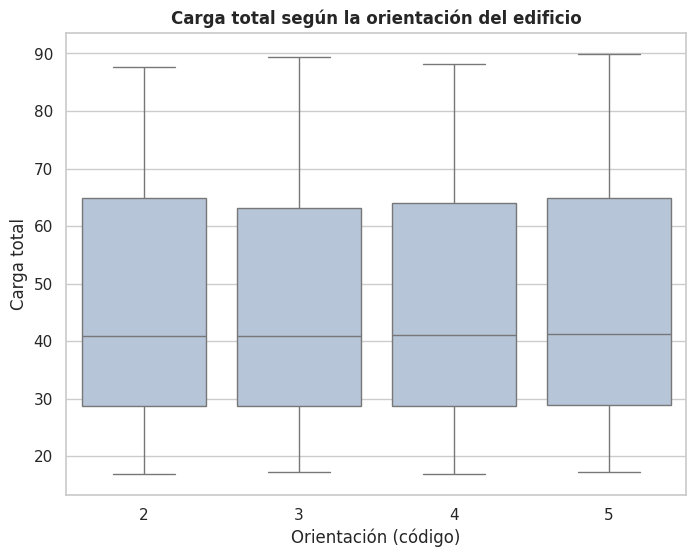

In [23]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="orientacion", y="carga_total", color="lightsteelblue")
plt.title("Carga total según la orientación del edificio", fontweight="bold")
plt.xlabel("Orientación (código)")
plt.ylabel("Carga total")
plt.show()

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
print("scikit-learn:", sklearn.__version__)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay, confusion_matrix)

scikit-learn: 1.6.1


**Preparar los datos**

In [25]:
# Variables predictoras: solo las de diseño (sin cargas, sin carga_total, sin forma_id)
columnas_X = ["compactacion_relativa", "area_superficie", "area_pared", "area_techo",
              "altura_total", "orientacion", "area_acristalamiento", "distribucion_acristalamiento"]
X = df[columnas_X]

# Variable objetivo (el capitalize deja las etiquetas como Alta, Media, Baja)
y = df["nivel_eficiencia"].astype(str).str.capitalize()

# Estandarizar: deja todas las variables en la misma escala
X_esc = StandardScaler().fit_transform(X)

print(X.shape)
print(y.value_counts())

(768, 8)
nivel_eficiencia
Media    256
Baja     256
Alta     256
Name: count, dtype: int64


**Parte 1: Clustering (K-means)**

elegir k

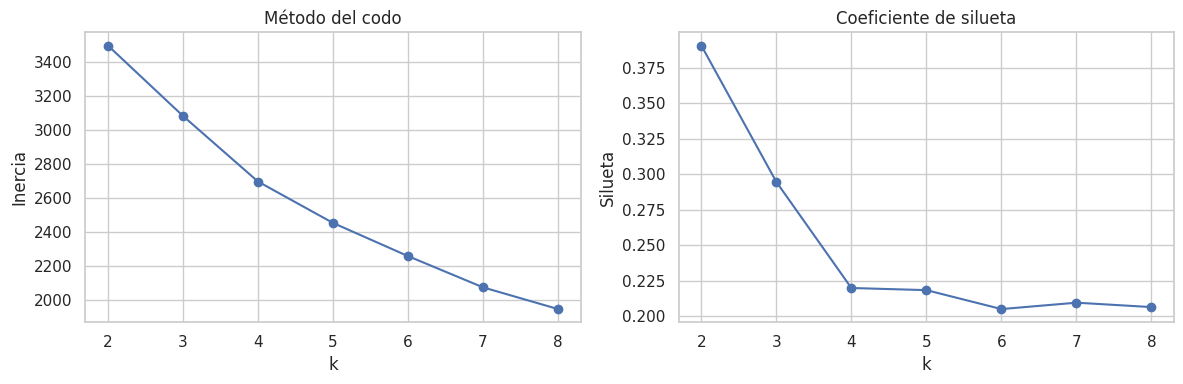

k = 2 | silueta = 0.391
k = 3 | silueta = 0.295
k = 4 | silueta = 0.22
k = 5 | silueta = 0.219
k = 6 | silueta = 0.205
k = 7 | silueta = 0.21
k = 8 | silueta = 0.207


In [26]:
inercias, siluetas = [], []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    etiquetas = km.fit_predict(X_esc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_esc, etiquetas))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(rango_k), inercias, marker="o")
ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(list(rango_k), siluetas, marker="o")
ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
plt.tight_layout()
plt.show()

for k, s in zip(rango_k, siluetas):
    print("k =", k, "| silueta =", round(s, 3))

Ajustar con el k elegido y ver el perfil de cada cluster

In [27]:
K_ELEGIDO = 2    # cámbialo si tu justificación apunta a otro valor

km = KMeans(n_clusters=K_ELEGIDO, random_state=SEED, n_init=10)
df["cluster"] = km.fit_predict(X_esc)

# Perfil: promedio de las variables originales por cluster
perfil = df.groupby("cluster")[columnas_X + ["carga_total"]].mean().round(2)
perfil["n_configuraciones"] = df["cluster"].value_counts().sort_index()
display(perfil.T)

print(pd.crosstab(df["cluster"], df["altura_total"]))
print(pd.crosstab(df["cluster"], y))

cluster,0,1
compactacion_relativa,0.68,0.85
area_superficie,747.25,596.17
area_pared,306.25,330.75
area_techo,220.50,132.71
altura_total,3.50,7.00
orientacion,3.50,3.50
area_acristalamiento,0.23,0.23
distribucion_acristalamiento,2.81,2.81
carga_total,29.41,64.38
n_configuraciones,384.00,384.00


altura_total  3.5  7.0
cluster               
0             384    0
1               0  384
nivel_eficiencia  Alta  Baja  Media
cluster                            
0                  256     0    128
1                    0   256    128


**PCA**

,componente,varianza,acumulada
0,1,0.463,0.463
1,2,0.155,0.618
2,3,0.152,0.769
3,4,0.125,0.894
4,5,0.098,0.993
5,6,0.007,0.999
6,7,0.001,1.000
7,8,0.000,1.000


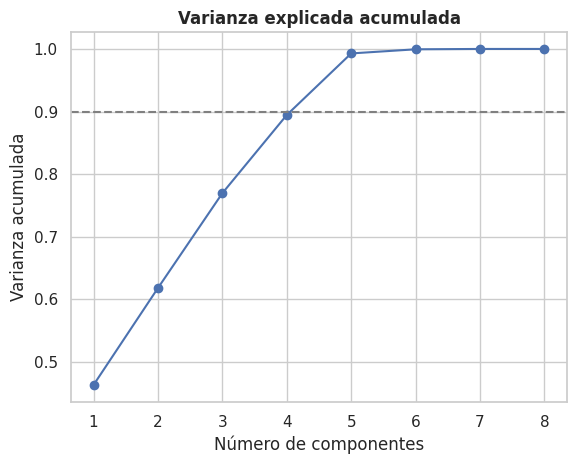

,PC1,PC2,PC3,PC4
compactacion_relativa,-0.50,-0.24,0.00,0.0
area_superficie,0.50,0.23,-0.00,0.0
area_pared,-0.03,0.89,-0.00,-0.0
area_techo,0.50,-0.21,0.00,-0.0
altura_total,-0.50,0.21,-0.00,0.0
orientacion,0.00,0.00,-0.00,1.0
area_acristalamiento,0.00,0.00,0.71,0.0
distribucion_acristalamiento,-0.00,0.00,0.71,0.0


Correlación PC1 con carga_total: -0.8


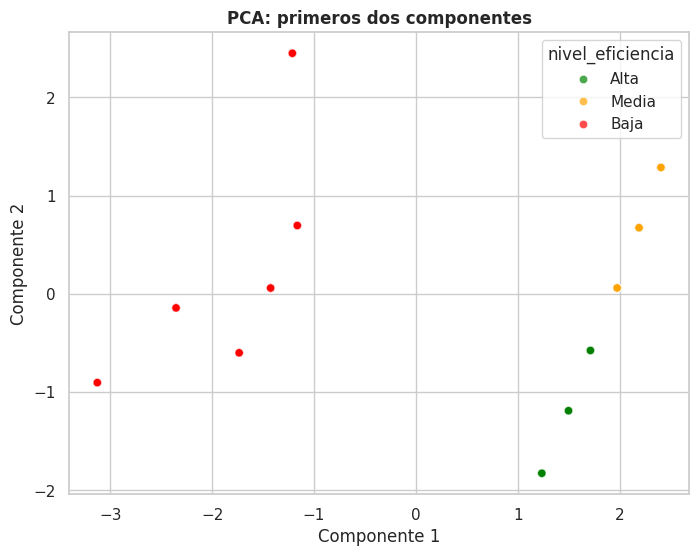

In [28]:
pca = PCA(random_state=SEED)
componentes = pca.fit_transform(X_esc)
var_acum = np.cumsum(pca.explained_variance_ratio_)

# Varianza explicada
tabla_var = pd.DataFrame({"componente": range(1, 9),
                          "varianza": pca.explained_variance_ratio_.round(3),
                          "acumulada": var_acum.round(3)})
display(tabla_var)

plt.plot(range(1, 9), var_acum, marker="o")
plt.axhline(0.9, linestyle="--", color="gray")
plt.title("Varianza explicada acumulada", fontweight="bold")
plt.xlabel("Número de componentes"); plt.ylabel("Varianza acumulada")
plt.show()

# Loadings: cuánto aporta cada variable a cada componente
loadings = pd.DataFrame(pca.components_[:4].T, index=columnas_X,
                        columns=["PC1", "PC2", "PC3", "PC4"]).round(2)
display(loadings)

# ¿El primer componente se relaciona con la carga total?
print("Correlación PC1 con carga_total:", round(np.corrcoef(componentes[:, 0], df["carga_total"])[0, 1], 2))

# Visualización 2D
plt.figure(figsize=(8, 6))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=y,
                hue_order=["Alta", "Media", "Baja"],
                palette={"Alta": "green", "Media": "orange", "Baja": "red"}, alpha=0.7)
plt.title("PCA: primeros dos componentes", fontweight="bold")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

**Clasificación**

Separar datos y entrenar los 3 modelos

In [29]:
# 75 % para entrenar, 25 % para probar; stratify mantiene la proporción de niveles
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

# El escalador aprende solo con los datos de entrenamiento
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

# Receta que calcula las métricas de un modelo (la usaremos varias veces)
def calcular_metricas(nombre, modelo, X_te, y_te):
    pred = modelo.predict(X_te)
    proba = modelo.predict_proba(X_te)
    return {"modelo": nombre,
            "accuracy": accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, average="macro"),
            "recall": recall_score(y_te, pred, average="macro"),
            "f1": f1_score(y_te, pred, average="macro"),
            "roc_auc": roc_auc_score(y_te, proba, multi_class="ovr", average="macro")}

modelos = {"Regresión logística": LogisticRegression(max_iter=1000, random_state=SEED),
           "Random Forest": RandomForestClassifier(random_state=SEED),
           "kNN": KNeighborsClassifier()}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train_esc, y_train)
    resultados.append(calcular_metricas(nombre, modelo, X_test_esc, y_test))

tabla_sin_lda = pd.DataFrame(resultados).round(3)
display(tabla_sin_lda)

,modelo,accuracy,precision,recall,f1,roc_auc
0,Regresión logística,0.802,0.798,0.802,0.796,0.954
1,Random Forest,0.948,0.949,0.948,0.947,0.992
2,kNN,0.911,0.911,0.911,0.911,0.979


Importancia de variables

In [30]:
rf = modelos["Random Forest"]
importancia = pd.Series(rf.feature_importances_, index=columnas_X).sort_values(ascending=False).round(3)
display(importancia)

log = modelos["Regresión logística"]
display(pd.DataFrame(log.coef_, index=log.classes_, columns=columnas_X).round(2).T)

,0
area_acristalamiento,0.228
area_superficie,0.217
compactacion_relativa,0.170
area_pared,0.098
area_techo,0.088
distribucion_acristalamiento,0.085
altura_total,0.079
orientacion,0.035


,Alta,Baja,Media
compactacion_relativa,-0.11,0.01,0.11
area_superficie,0.65,-0.33,-0.32
area_pared,-1.62,1.57,0.04
area_techo,1.42,-1.09,-0.33
altura_total,-1.68,2.34,-0.66
orientacion,-0.07,0.07,0.00
area_acristalamiento,-1.51,1.40,0.11
distribucion_acristalamiento,0.10,0.03,-0.13


Matriz de confusión y costo del error

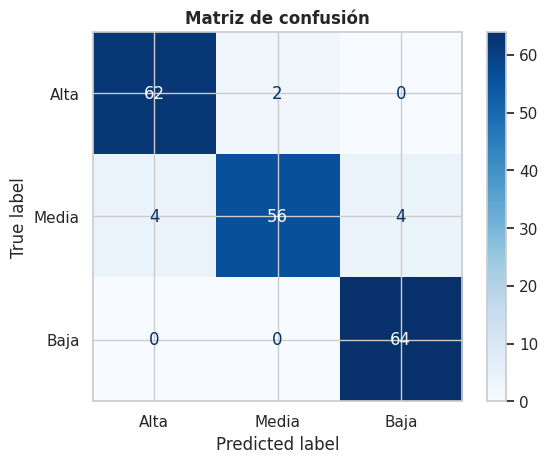

[[62  2  0]
 [ 4 56  4]
 [ 0  0 64]]
Baja predicha como Alta: 0
Alta predicha como Baja: 0


In [31]:
mejor = modelos["Random Forest"]     # cambia por el modelo que elijas
pred_mejor = mejor.predict(X_test_esc)

ConfusionMatrixDisplay.from_predictions(y_test, pred_mejor,
                                        labels=["Alta", "Media", "Baja"], cmap="Blues")
plt.title("Matriz de confusión", fontweight="bold")
plt.show()

cm = confusion_matrix(y_test, pred_mejor, labels=["Alta", "Media", "Baja"])
print(cm)
print("Baja predicha como Alta:", cm[2, 0])
print("Alta predicha como Baja:", cm[0, 2])

Robustez, validando por forma de edificio

In [32]:
# 1. Crear 'forma_id' identificando combinaciones únicas de dimensiones estructurales
columnas_forma = ["compactacion_relativa", "area_superficie", "area_pared", "area_techo", "altura_total"]
df["forma_id"] = df.groupby(columnas_forma).ngroup()

grupos = df["forma_id"]
cv_forma = GroupKFold(n_splits=4)

filas = []
for nombre, modelo in [("Regresión logística", LogisticRegression(max_iter=1000, random_state=SEED)),
                       ("Random Forest", RandomForestClassifier(random_state=SEED)),
                       ("kNN", KNeighborsClassifier())]:
    # make_pipeline escala dentro de cada fold, para no filtrar información
    puntajes = cross_val_score(make_pipeline(StandardScaler(), modelo), X, y,
                               groups=grupos, cv=cv_forma, scoring="accuracy")
    filas.append({"modelo": nombre, "accuracy_medio": puntajes.mean(),
                  "desviacion": puntajes.std(), "minimo": puntajes.min(), "maximo": puntajes.max()})

display(pd.DataFrame(filas).round(3))

,modelo,accuracy_medio,desviacion,minimo,maximo
0,Regresión logística,0.622,0.162,0.474,0.885
1,Random Forest,0.585,0.067,0.510,0.651
2,kNN,0.570,0.073,0.500,0.677


**LDA**

Varianza explicada por cada eje: [0.973 0.027]


,LD1,LD2
compactacion_relativa,-0.36,10.25
area_superficie,-0.05,6.09
area_pared,0.36,2.11
area_techo,-0.47,7.99
altura_total,1.72,3.91
orientacion,0.04,0.02
area_acristalamiento,0.70,0.16
distribucion_acristalamiento,-0.04,-0.25


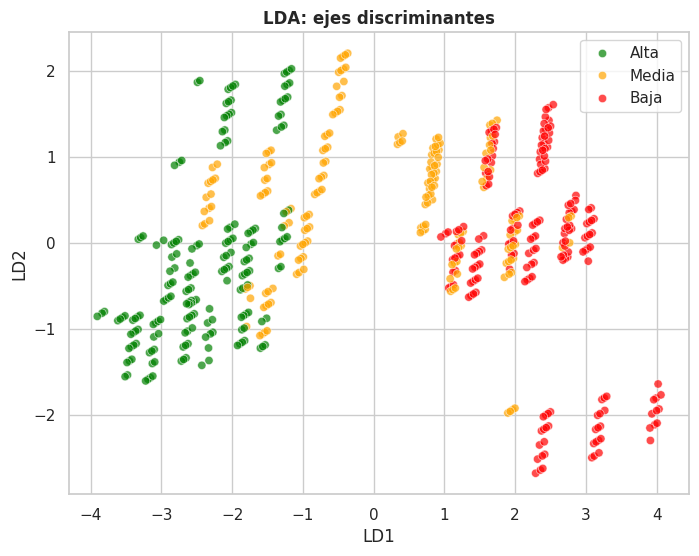

In [33]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_esc, y_train)
X_test_lda = lda.transform(X_test_esc)

print("Varianza explicada por cada eje:", lda.explained_variance_ratio_.round(3))
display(pd.DataFrame(lda.scalings_[:, :2], index=columnas_X, columns=["LD1", "LD2"]).round(2))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_lda[:, 0], y=X_train_lda[:, 1], hue=y_train.values,
                hue_order=["Alta", "Media", "Baja"],
                palette={"Alta": "green", "Media": "orange", "Baja": "red"}, alpha=0.7)
plt.title("LDA: ejes discriminantes", fontweight="bold")
plt.xlabel("LD1"); plt.ylabel("LD2")
plt.show()

# Los mismos 3 modelos, ahora entrenados con los 2 ejes de LDA
modelos_lda = {"Regresión logística + LDA": LogisticRegression(max_iter=1000, random_state=SEED),
               "Random Forest + LDA": RandomForestClassifier(random_state=SEED),
               "kNN + LDA": KNeighborsClassifier()}

resultados_lda = []
for nombre, modelo in modelos_lda.items():
    modelo.fit(X_train_lda, y_train)
    resultados_lda.append(calcular_metricas(nombre, modelo, X_test_lda, y_test))

tabla_con_lda = pd.DataFrame(resultados_lda).round(3)

**Tabla final de comparación**

In [34]:
tabla_final = pd.concat([tabla_sin_lda, tabla_con_lda], ignore_index=True)
display(tabla_final)

,modelo,accuracy,precision,recall,f1,roc_auc
0,Regresión logística,0.802,0.798,0.802,0.796,0.954
1,Random Forest,0.948,0.949,0.948,0.947,0.992
2,kNN,0.911,0.911,0.911,0.911,0.979
3,Regresión logística + LDA,0.807,0.804,0.807,0.800,0.949
4,Random Forest + LDA,0.875,0.875,0.875,0.875,0.981
5,kNN + LDA,0.849,0.851,0.849,0.850,0.973
